In [2]:
import sys
import os
sys.path.append(os.path.abspath("../src"))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from data_loader import load_transaction_data
from fraud_detection import flag_suspicious_transactions 

# Load the data
df = load_transaction_data("../data/fraudTrain.csv")

df["hour"] = df["trans_date_trans_time"].dt.hour
# Quick check
df.info()
df.head()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 24 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   unnamed: 0             1296675 non-null  int64         
 1   trans_date_trans_time  1296675 non-null  datetime64[ns]
 2   cc_num                 1296675 non-null  int64         
 3   merchant               1296675 non-null  object        
 4   category               1296675 non-null  object        
 5   amt                    1296675 non-null  float64       
 6   first                  1296675 non-null  object        
 7   last                   1296675 non-null  object        
 8   gender                 1296675 non-null  object        
 9   street                 1296675 non-null  object        
 10  city                   1296675 non-null  object        
 11  state                  1296675 non-null  object        
 12  zip                    12966

,unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,hour
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,0


In [ ]:
print("Total Transactions:", len(df))
print("Total Amount Spent: $", df['amt'].sum())
print("Average Amount per Transaction: $", df['amt'].mean())


🔹 Total Transactions: 1296675
🔹 Total Amount Spent: $ 91222428.89999999
🔹 Average Amount per Transaction: $ 70.35103545607032


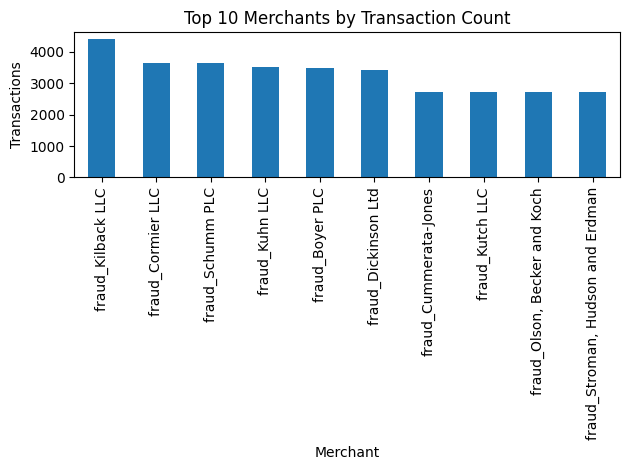

In [7]:
top_merchants = df['merchant'].value_counts().head(10)
top_merchants.plot(kind='bar', title="Top 10 Merchants by Transaction Count")
plt.xlabel("Merchant")
plt.ylabel("Transactions")
plt.tight_layout()
plt.show()



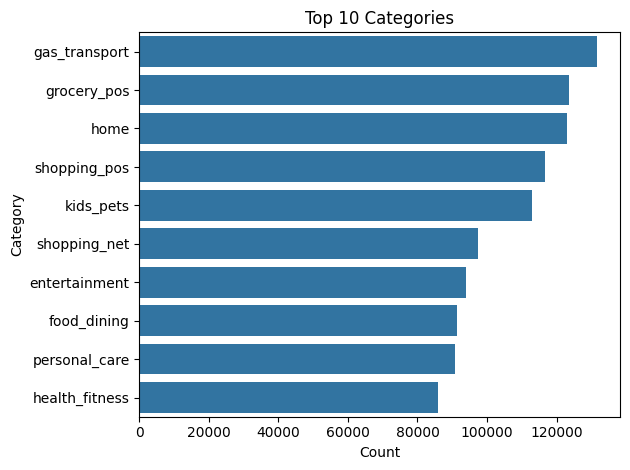

In [8]:
top_categories = df['category'].value_counts().head(10)
sns.barplot(x=top_categories.values, y=top_categories.index)
plt.title("Top 10 Categories")
plt.xlabel("Count")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


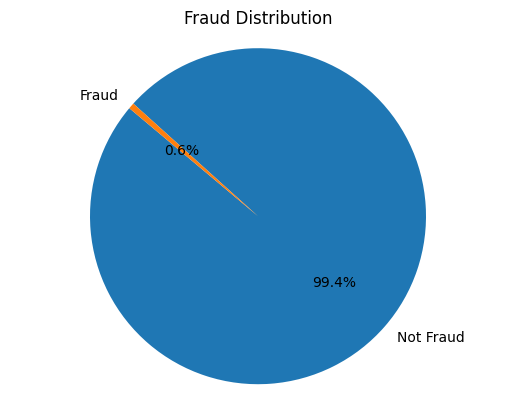

In [9]:
fraud_counts = df['is_fraud'].value_counts()
labels = ['Not Fraud', 'Fraud']
plt.pie(fraud_counts, labels=labels, autopct='%1.1f%%', startangle=140)
plt.axis('equal')
plt.title("Fraud Distribution")
plt.show()


In [10]:
df.groupby('category')['is_fraud'].mean().sort_values(ascending=False).head(10)


category
shopping_net     0.017561
misc_net         0.014458
grocery_pos      0.014098
shopping_pos     0.007225
gas_transport    0.004694
misc_pos         0.003139
grocery_net      0.002948
travel           0.002864
entertainment    0.002478
personal_care    0.002424
Name: is_fraud, dtype: float64

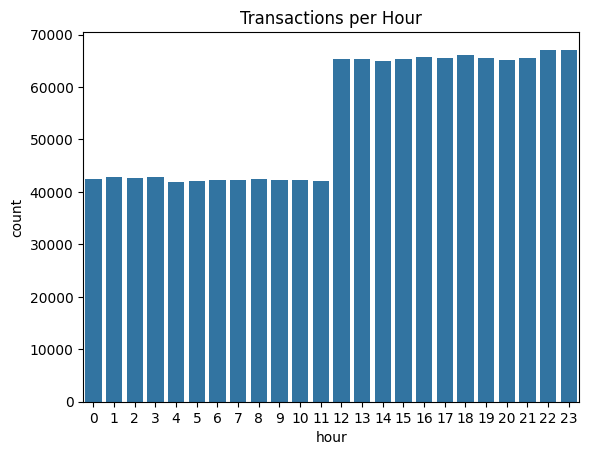

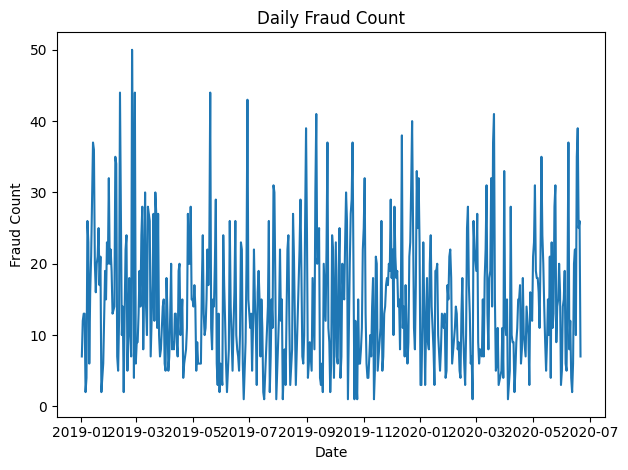

In [11]:
df['hour'] = df['trans_date_trans_time'].dt.hour
df['day'] = df['trans_date_trans_time'].dt.date

# Transactions per hour
sns.countplot(x='hour', data=df)
plt.title("Transactions per Hour")
plt.show()

# Total frauds over time
daily_frauds = df[df['is_fraud'] == 1].groupby('day').size()
daily_frauds.plot(title="Daily Fraud Count")
plt.xlabel("Date")
plt.ylabel("Fraud Count")
plt.tight_layout()
plt.show()


C:\Users\soufi\AppData\Local\Temp\ipykernel_10160\2692197070.py:12: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\soufi\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


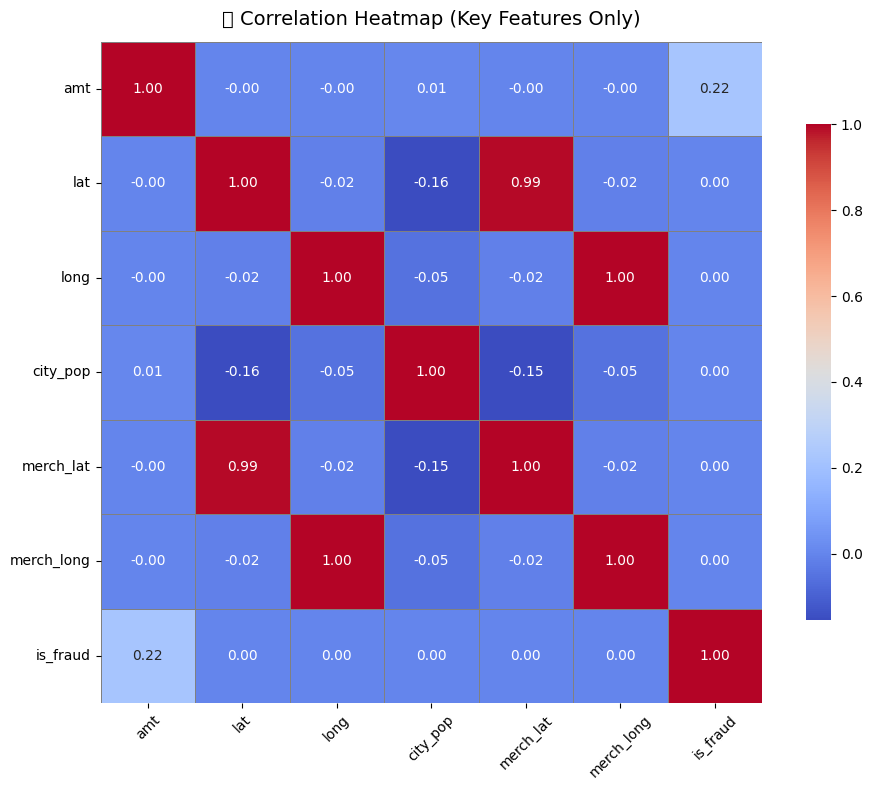

In [4]:

cols_to_include = ['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long', 'is_fraud']
corr_matrix = df[cols_to_include].corr()

# Plot with better aesthetics
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True,
            linewidths=0.5, linecolor='gray', cbar_kws={"shrink": 0.75})

plt.title("🔍 Correlation Heatmap (Key Features Only)", fontsize=14, pad=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [6]:


# Apply fraud rules
df_flagged = flag_suspicious_transactions(df)

# See how many were flagged
print("🔍 Total suspicious transactions:", df_flagged["is_suspicious"].sum())

# Preview flagged transactions
df_flagged[df_flagged["is_suspicious"] == True].head()


🔍 Total suspicious transactions: 284883


,unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,hour,is_suspicious
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,0,True
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,0,True
9,9,2019-01-01 00:06:01,2720830304681674,"fraud_Schoen, Kuphal and Nitzsche",grocery_pos,198.39,Melissa,Aguilar,F,21326 Taylor Squares Suite 708,...,151785,Pathologist,1974-03-28,3b9014ea8fb80bd65de0b1463b00b00e,1325376361,37.179198,-87.485381,0,0,True
10,10,2019-01-01 00:06:23,4642894980163,fraud_Rutherford-Mertz,grocery_pos,24.74,Eddie,Mendez,M,1831 Faith View Suite 653,...,7297,IT trainer,1990-07-13,d71c95ab6b7356dd74389d41df429c87,1325376383,40.275891,-96.011548,0,0,True
11,11,2019-01-01 00:06:53,377234009633447,fraud_Kerluke-Abshire,shopping_net,7.77,Theresa,Blackwell,F,43576 Kristina Islands,...,1925,Systems developer,1966-02-14,3c74776e558f1499a7824b556e474b1d,1325376413,40.103866,-78.624459,0,0,True


In [7]:
from sklearn.metrics import confusion_matrix, classification_report

print(classification_report(df_flagged["is_fraud"], df_flagged["is_suspicious"]))


              precision    recall  f1-score   support

           0       1.00      0.78      0.88   1289169
           1       0.02      0.58      0.03      7506

    accuracy                           0.78   1296675
   macro avg       0.51      0.68      0.45   1296675
weighted avg       0.99      0.78      0.87   1296675



In [3]:
# In a notebook or script
frauds = df[df["is_fraud"] == 1].sample(5)
print(frauds[["amt", "hour", "category", "job", "city_pop"]])


            amt  hour       category                        job  city_pop
199097   929.44    22   shopping_net  Learning disability nurse       800
272915    11.91     0  gas_transport                    Curator      4198
229139   792.33     2       misc_net                   Musician    493806
81717    327.16     2    grocery_pos               Psychiatrist       397
1123649  274.87     2    grocery_pos                Firefighter    105549
